## *Experiment 05: Hierarchical Two-Stage VAE + SupCon + Ensemble cho FiveDataset*

### Ý tưởng — cải tiến so với ex04

Bài toán khó nhất vẫn là cụm:
- `AML`
- `CML`
- `MDS`

ex05 kế thừa kiến trúc 2-stage của ex03/ex04 và bổ sung **4 cải tiến chính**:

#### Cải tiến 1 — SMOTE-Tomek thay WeightedRandomSampler thuần
Học từ [9] (W-CNN 99.9%) và [13] (MRMR Ensemble 95.83%): oversampling bằng SMOTE-Tomek tạo mẫu tổng hợp thực sự cho lớp thiểu số thay vì chỉ reweight, giúp classifier thấy nhiều variation hơn.

#### Cải tiến 2 — Variational Autoencoder (VAE) thay Denoising AE
VAE ép latent space thành phân phối Gaussian qua KL divergence → latent smooth hơn, generalize tốt hơn với AML/CML/MDS ít mẫu. Loss = recon_loss + β × KL_loss.

#### Cải tiến 3 — Supervised Contrastive Loss (SupCon) cho Stage 2
SupConLoss kéo xa embedding của 3 lớp Myeloid trong latent space, giải quyết trực tiếp vấn đề AML/CML/MDS quá giống nhau. Fine-tune với: FocalLoss + λ_recon × MSE + λ_supcon × SupCon.

#### Cải tiến 4 — Soft Ensemble: VAE-MLP + XGBoost trên latent
Học từ [10] (CNN+SVM voting 97%) và [15] (DNN+SVM+NB+KNN 98.2%): sau khi VAE encode, train thêm XGBClassifier trên latent vector rồi soft-voting xác suất với ResidualMLP.

### Pipeline tổng thể
```
Stage 1: SelectKBest(Chi²) → SMOTE-Tomek → ResidualMLP (4 lớp)
Stage 2: SelectKBest(Chi²) → SMOTE-Tomek → VAE pretrain
       → Fine-tune (FocalLoss + KL + SupCon)
       → Latent vector → [ResidualMLP | XGBoost] → soft voting
```

### Bước 1. Import thư viện và khởi tạo thư mục output

In [2]:
%pip install xgboost imbalanced-learn


   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---

In [3]:
import os
import re
import copy
import random
import zipfile
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.feature_selection import SelectKBest, chi2, f_classif
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler, label_binarize
from xgboost import XGBClassifier
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

warnings.filterwarnings("ignore")


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_next_run_dir(model_root: Path) -> Path:
    model_root.mkdir(parents=True, exist_ok=True)
    pattern = re.compile(r"run(\d+)$")
    nums = []
    for p in model_root.iterdir():
        if p.is_dir():
            m = pattern.match(p.name)
            if m:
                nums.append(int(m.group(1)))
    next_num = 1 if not nums else max(nums) + 1
    return model_root / f"run{next_num:02d}"


def load_five_dataset(data_dir: Path, class_col: str = "Class") -> pd.DataFrame:
    csv_path = data_dir / "FiveDataset.csv"
    zip_path = data_dir / "FiveDataset.zip"

    if csv_path.exists():
        df = pd.read_csv(csv_path)
    elif zip_path.exists():
        with zipfile.ZipFile(zip_path, "r") as zf:
            target = None
            for name in zf.namelist():
                if name.lower().endswith(".csv") and "fivedataset" in name.lower():
                    target = name
                    break
            if target is None:
                candidates = [n for n in zf.namelist() if n.lower().endswith(".csv")]
                if not candidates:
                    raise FileNotFoundError("Không tìm thấy file CSV trong FiveDataset.zip")
                target = candidates[0]
            with zf.open(target) as f:
                df = pd.read_csv(f)
    else:
        raise FileNotFoundError("Không tìm thấy FiveDataset.csv hoặc FiveDataset.zip trong data/raw")

    if class_col not in df.columns:
        raise ValueError(f"Không tìm thấy cột nhãn '{class_col}'")
    return df


seed_everything(42)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"
EXPERIMENT_ROOT = PROJECT_ROOT / "outputs" / "ex05"
RUN_DIR = get_next_run_dir(EXPERIMENT_ROOT)

FIG_DIR = RUN_DIR / "figures"
METRIC_DIR = RUN_DIR / "metrics"
MODEL_DIR = RUN_DIR / "models"

for d in [FIG_DIR, METRIC_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR:", DATA_DIR)
print("RUN_DIR:", RUN_DIR)
print("DEVICE:", DEVICE)

PROJECT_ROOT: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl
DATA_DIR: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl\data\raw
RUN_DIR: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl\outputs\ex05\run01
DEVICE: cpu


### Bước 2. Khai báo cấu hình

Các tham số được điều chỉnh phù hợp với từng cải tiến mới.

In [4]:
CLASS_COL = "Class"
TEST_SIZE = 0.15
VAL_SIZE = 0.15
RANDOM_STATE = 42

# ── Feature selection ──────────────────────────────────────────────────────────
# Dùng Chi² (cần MinMax scale về [0,1]) thay ANOVA F-test
# Học từ [9] W-CNN (99.9%) và [10] CNN+SVM (97%)
TOP_K_STAGE1 = 1000
TOP_K_STAGE2 = 900

# ── Stage 1 ────────────────────────────────────────────────────────────────────
STAGE1_BATCH_SIZE = 32
STAGE1_EPOCHS     = 50
STAGE1_LR         = 5e-4
STAGE1_WEIGHT_DECAY = 3e-4
STAGE1_DROPOUT    = 0.30
STAGE1_PATIENCE   = 10
STAGE1_HIDDEN_DIMS = (256, 128)
STAGE1_LABEL_SMOOTH = 0.05   # Label smoothing ε

# ── VAE Stage 2 pretrain ───────────────────────────────────────────────────────
LATENT_DIM_STAGE2   = 96
VAE_BATCH_SIZE      = 32
VAE_EPOCHS          = 50
VAE_LR              = 1e-3
VAE_WEIGHT_DECAY    = 1e-4
VAE_DROPOUT         = 0.10
VAE_PATIENCE        = 8
VAE_BETA            = 0.5    # β-VAE: weight của KL divergence

# ── Stage 2 fine-tune ──────────────────────────────────────────────────────────
STAGE2_BATCH_SIZE   = 32
STAGE2_EPOCHS       = 60
STAGE2_ENCODER_LR   = 2e-4
STAGE2_DECODER_LR   = 1e-4
STAGE2_HEAD_LR      = 6e-4
STAGE2_WEIGHT_DECAY = 4e-4
STAGE2_DROPOUT      = 0.28
STAGE2_PATIENCE     = 10
STAGE2_HIDDEN_DIMS  = (192, 96)

# Joint loss = FocalLoss + λ_recon * MSE + λ_supcon * SupConLoss
RECON_LOSS_WEIGHT   = 0.10
SUPCON_LOSS_WEIGHT  = 0.30
SUPCON_TEMPERATURE  = 0.07   # Temperature của SupConLoss

STAGE2_CLASS_BOOST = {
    "AML": 1.10,
    "CML": 1.18,
    "MDS": 1.12
}

# ── XGBoost ensemble ──────────────────────────────────────────────────────────
XGB_N_ESTIMATORS  = 300
XGB_MAX_DEPTH     = 4
XGB_LR_XGB       = 0.05
XGB_SUBSAMPLE     = 0.8
XGB_COL_BYTREE    = 0.8

# Trọng số soft-voting: MLP vs XGBoost
ENSEMBLE_WEIGHT_MLP = 0.60
ENSEMBLE_WEIGHT_XGB = 0.40

print("TOP_K_STAGE1       =", TOP_K_STAGE1)
print("TOP_K_STAGE2       =", TOP_K_STAGE2)
print("LATENT_DIM_STAGE2  =", LATENT_DIM_STAGE2)
print("VAE_BETA           =", VAE_BETA)
print("SUPCON_LOSS_WEIGHT =", SUPCON_LOSS_WEIGHT)
print("ENSEMBLE MLP/XGB   =", ENSEMBLE_WEIGHT_MLP, "/", ENSEMBLE_WEIGHT_XGB)

TOP_K_STAGE1       = 1000
TOP_K_STAGE2       = 900
LATENT_DIM_STAGE2  = 96
VAE_BETA           = 0.5
SUPCON_LOSS_WEIGHT = 0.3
ENSEMBLE MLP/XGB   = 0.6 / 0.4


### Bước 3. Định nghĩa Dataset, model và các hàm train/evaluate

Các thành phần mới so với ex04:
- `VariationalAutoencoder` — encoder trả về (mu, log_var), reparameterize trick
- `SupConLoss` — supervised contrastive loss
- `LabelSmoothingCrossEntropy` — cross entropy có label smoothing
- `JointVAEStage2Model` — encoder VAE + decoder + classifier ResidualMLP
- Hàm `run_stage2_vae_epoch` — tích hợp 3 loss

In [5]:
# ─────────────────────────────────────────────────────────────────────────────
# Dataset
# ─────────────────────────────────────────────────────────────────────────────

class GeneDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


class UnlabeledDataset(Dataset):
    def __init__(self, X):
        self.X = torch.tensor(X, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx]


# ─────────────────────────────────────────────────────────────────────────────
# Models
# ─────────────────────────────────────────────────────────────────────────────

class ResidualMLPClassifier(nn.Module):
    """Residual MLP với BatchNorm + GELU, kế thừa từ ex03/ex04."""

    def __init__(self, input_dim: int, hidden_dims=(256, 128), num_classes: int = 2, dropout: float = 0.3):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, hidden_dims[0])

        blocks = []
        prev_dim = hidden_dims[0]
        for h in hidden_dims:
            blocks.append(nn.Sequential(
                nn.Linear(prev_dim, h),
                nn.BatchNorm1d(h),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(h, h),
                nn.BatchNorm1d(h)
            ))
            prev_dim = h

        self.blocks = nn.ModuleList(blocks)
        self.activ = nn.GELU()
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_dims[-1], num_classes)

    def forward(self, x):
        x = self.input_proj(x)
        for block in self.blocks:
            residual = x
            out = block(x)
            if out.shape == residual.shape:
                x = self.activ(out + residual)
            else:
                x = self.activ(out)
            x = self.drop(x)
        return self.head(x)


class VariationalAutoencoder(nn.Module):
    """
    Variational Autoencoder (VAE).
    Encoder → (mu, log_var) → reparameterize → z → Decoder → x_hat
    Loss = MSE(x_hat, x) + β * KL(N(mu,var) || N(0,1))
    """

    def __init__(self, input_dim: int, latent_dim: int = 96, dropout: float = 0.10):
        super().__init__()

        # Encoder backbone
        self.encoder_backbone = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        # Hai head riêng biệt cho mu và log_var
        self.fc_mu      = nn.Linear(128, latent_dim)
        self.fc_log_var = nn.Linear(128, latent_dim)

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(512, input_dim)
        )

    def encode(self, x):
        h = self.encoder_backbone(x)
        mu      = self.fc_mu(h)
        log_var = self.fc_log_var(h)
        return mu, log_var

    def reparameterize(self, mu, log_var):
        """Reparameterization trick: z = mu + eps * std"""
        if self.training:
            std = torch.exp(0.5 * log_var)
            eps = torch.randn_like(std)
            return mu + eps * std
        return mu  # Khi inference: dùng mu trực tiếp

    def forward(self, x):
        mu, log_var = self.encode(x)
        z = self.reparameterize(mu, log_var)
        x_hat = self.decoder(z)
        return z, x_hat, mu, log_var


class JointVAEStage2Model(nn.Module):
    """
    Fine-tune end-to-end: encoder VAE + decoder + ResidualMLP classifier.
    Forward trả về (logits, x_hat, z, mu, log_var) để tính đủ 3 loss.
    """

    def __init__(self, pretrained_vae: nn.Module, latent_dim: int,
                 hidden_dims=(192, 96), num_classes=3, dropout=0.28):
        super().__init__()
        self.encoder_backbone = copy.deepcopy(pretrained_vae.encoder_backbone)
        self.fc_mu             = copy.deepcopy(pretrained_vae.fc_mu)
        self.fc_log_var        = copy.deepcopy(pretrained_vae.fc_log_var)
        self.decoder           = copy.deepcopy(pretrained_vae.decoder)
        self.classifier = ResidualMLPClassifier(
            input_dim=latent_dim,
            hidden_dims=hidden_dims,
            num_classes=num_classes,
            dropout=dropout
        )

    def encode(self, x):
        h       = self.encoder_backbone(x)
        mu      = self.fc_mu(h)
        log_var = self.fc_log_var(h)
        return mu, log_var

    def reparameterize(self, mu, log_var):
        if self.training:
            std = torch.exp(0.5 * log_var)
            eps = torch.randn_like(std)
            return mu + eps * std
        return mu

    def forward(self, x):
        mu, log_var = self.encode(x)
        z           = self.reparameterize(mu, log_var)
        x_hat       = self.decoder(z)
        logits      = self.classifier(z)
        return logits, x_hat, z, mu, log_var


# ─────────────────────────────────────────────────────────────────────────────
# Loss functions
# ─────────────────────────────────────────────────────────────────────────────

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, reduction="mean"):
        super().__init__()
        self.alpha     = alpha
        self.gamma     = gamma
        self.reduction = reduction

    def forward(self, logits, targets):
        ce_loss   = F.cross_entropy(logits, targets, weight=self.alpha, reduction="none")
        pt        = torch.exp(-ce_loss)
        focal     = ((1 - pt) ** self.gamma) * ce_loss
        return focal.mean() if self.reduction == "mean" else focal.sum()


class LabelSmoothingCrossEntropy(nn.Module):
    """
    Cross-entropy với label smoothing ε.
    Học từ [16] TabNet paper: label smoothing giảm overconfidence,
    đặc biệt hiệu quả cho Stage 1 phân loại nhóm Myeloid.
    """

    def __init__(self, num_classes: int, smoothing: float = 0.05, weight=None):
        super().__init__()
        self.smoothing   = smoothing
        self.num_classes = num_classes
        self.weight      = weight

    def forward(self, logits, targets):
        log_probs = F.log_softmax(logits, dim=-1)
        # One-hot smooth target
        with torch.no_grad():
            smooth_targets = torch.full_like(log_probs, self.smoothing / (self.num_classes - 1))
            smooth_targets.scatter_(1, targets.unsqueeze(1), 1.0 - self.smoothing)

        loss = -(smooth_targets * log_probs).sum(dim=-1)

        if self.weight is not None:
            w    = self.weight[targets]
            loss = loss * w

        return loss.mean()


class SupConLoss(nn.Module):
    """
    Supervised Contrastive Loss.
    Kéo xa embedding của các lớp Myeloid (AML vs CML vs MDS) trong latent space.
    Ref: Khosla et al. 2020 - Supervised Contrastive Learning.
    """

    def __init__(self, temperature: float = 0.07):
        super().__init__()
        self.temperature = temperature

    def forward(self, features, labels):
        """
        features: (N, D) — normalized latent vectors
        labels:   (N,)   — class indices
        """
        device = features.device
        N      = features.shape[0]

        if N < 2:
            return torch.tensor(0.0, device=device)

        # L2-normalize
        features = F.normalize(features, p=2, dim=1)

        # Similarity matrix (N x N)
        sim_matrix = torch.matmul(features, features.T) / self.temperature

        # Mask self-contrast
        self_mask = torch.eye(N, dtype=torch.bool, device=device)
        sim_matrix = sim_matrix.masked_fill(self_mask, -1e9)

        # Positive mask: same label, khác nhau
        labels_col = labels.unsqueeze(1)
        labels_row = labels.unsqueeze(0)
        pos_mask = (labels_col == labels_row) & ~self_mask

        # Log-sum-exp denominator
        log_denom = torch.logsumexp(sim_matrix, dim=1)  # (N,)

        # Chỉ tính loss cho sample có ít nhất 1 positive
        num_positives = pos_mask.sum(1).float()
        has_positive  = num_positives > 0

        if has_positive.sum() == 0:
            return torch.tensor(0.0, device=device)

        # Sum log-prob of positives
        log_prob  = sim_matrix - log_denom.unsqueeze(1)            # (N, N)
        loss_mat  = -(log_prob * pos_mask.float())                 # (N, N)
        loss_per  = loss_mat.sum(1) / num_positives.clamp(min=1)   # (N,)

        return loss_per[has_positive].mean()


def vae_kl_loss(mu, log_var):
    """KL divergence: KL(N(mu,var) || N(0,1))"""
    return -0.5 * torch.mean(1 + log_var - mu.pow(2) - log_var.exp())


# ─────────────────────────────────────────────────────────────────────────────
# Training loops
# ─────────────────────────────────────────────────────────────────────────────

def run_stage1_epoch(model, loader, criterion, device, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    all_preds, all_targets = [], []

    with torch.set_grad_enabled(is_train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits  = model(xb)
            loss    = criterion(logits, yb)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            total_loss += loss.item() * xb.size(0)
            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(yb.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc      = accuracy_score(all_targets, all_preds)
    macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    return avg_loss, acc, macro_f1


def train_vae_epoch(model, loader, criterion_recon, optimizer, device, beta=0.5):
    """Pretrain VAE: loss = MSE + β * KL"""
    model.train()
    total_loss = 0.0

    for xb in loader:
        xb = xb.to(device)
        _, x_hat, mu, log_var = model(xb)
        recon = criterion_recon(x_hat, xb)
        kl    = vae_kl_loss(mu, log_var)
        loss  = recon + beta * kl

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item() * xb.size(0)

    return total_loss / len(loader.dataset)


def eval_vae_epoch(model, loader, criterion_recon, device, beta=0.5):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for xb in loader:
            xb = xb.to(device)
            _, x_hat, mu, log_var = model(xb)
            recon = criterion_recon(x_hat, xb)
            kl    = vae_kl_loss(mu, log_var)
            loss  = recon + beta * kl
            total_loss += loss.item() * xb.size(0)
    return total_loss / len(loader.dataset)


def run_stage2_vae_epoch(
    model, loader,
    cls_criterion, recon_criterion, supcon_criterion,
    recon_weight, supcon_weight, vae_beta,
    device, optimizer=None
):
    """
    Fine-tune joint model.
    total_loss = FocalLoss + λ_recon*(MSE + β*KL) + λ_supcon*SupConLoss
    """
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = total_cls = total_recon = total_kl = total_supcon = 0.0
    all_preds, all_targets = [], []

    with torch.set_grad_enabled(is_train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)

            logits, x_hat, z, mu, log_var = model(xb)

            cls_loss   = cls_criterion(logits, yb)
            recon_loss = recon_criterion(x_hat, xb)
            kl_loss    = vae_kl_loss(mu, log_var)
            sc_loss    = supcon_criterion(z, yb)

            loss = (cls_loss
                    + recon_weight * (recon_loss + vae_beta * kl_loss)
                    + supcon_weight * sc_loss)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            n = xb.size(0)
            total_loss   += loss.item() * n
            total_cls    += cls_loss.item() * n
            total_recon  += recon_loss.item() * n
            total_kl     += kl_loss.item() * n
            total_supcon += sc_loss.item() * n

            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(yb.cpu().numpy())

    dset_size = len(loader.dataset)
    return (
        total_loss / dset_size,
        total_cls / dset_size,
        total_recon / dset_size,
        total_kl / dset_size,
        total_supcon / dset_size,
        accuracy_score(all_targets, all_preds),
        f1_score(all_targets, all_preds, average="macro", zero_division=0)
    )


def predict_proba_stage1(model, loader, device):
    model.eval()
    all_probs, all_preds, all_targets = [], [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb     = xb.to(device)
            logits = model(xb)
            probs  = torch.softmax(logits, dim=1)
            preds  = torch.argmax(probs, dim=1)
            all_probs.append(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(yb.numpy())
    return np.array(all_targets), np.array(all_preds), np.vstack(all_probs)


def extract_latent_and_proba(model, loader, device):
    """Trích latent z (dùng cho XGBoost) và xác suất MLP (dùng cho ensemble)."""
    model.eval()
    all_z, all_probs, all_preds, all_targets = [], [], [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            logits, _, z, _, _ = model(xb)
            probs  = torch.softmax(logits, dim=1)
            preds  = torch.argmax(probs, dim=1)
            all_z.append(z.cpu().numpy())
            all_probs.append(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(yb.numpy())
    return (
        np.array(all_targets),
        np.array(all_preds),
        np.vstack(all_probs),
        np.vstack(all_z)
    )


print("Đã định nghĩa xong toàn bộ classes và functions.")

Đã định nghĩa xong toàn bộ classes và functions.


### Bước 4. Load dữ liệu FiveDataset

In [6]:
df = load_five_dataset(DATA_DIR, class_col=CLASS_COL)
gene_cols = [c for c in df.columns if c not in ["Unnamed: 0", CLASS_COL]]

print("Kích thước dữ liệu:", df.shape)
print("Số gene:", len(gene_cols))
display(df.head())

class_distribution = df[CLASS_COL].value_counts().sort_index()
display(class_distribution.to_frame("count"))
class_distribution.to_csv(METRIC_DIR / "class_distribution_6class.csv")

Kích thước dữ liệu: (2521, 21357)
Số gene: 21355


,Unnamed: 0,DDR1,RFC2,HSPA6,PAX8,GUCA1A,UBA7,THRA,PTPN21,CCL5,...,NQO2-AS1,ITGB1-DT,TNFRSF10A-DT,LOC400499,GALR3,ZNF710-AS1,SAP25,TMEM231,LOC100505915,Class
0,GSM329407,5.849528,7.511939,7.226272,4.658426,4.386529,8.436415,4.734517,3.706727,10.559860,...,3.414406,4.034259,4.592081,6.340251,5.661825,6.559102,6.754030,3.918783,6.285588,ALL
1,GSM329408,6.766342,8.540821,6.708342,4.799562,4.259775,8.387226,5.014696,3.708090,6.340428,...,3.644112,4.364029,4.299601,6.040011,5.552325,6.617199,6.298633,3.888387,6.737579,ALL
2,GSM329409,6.338627,6.997434,5.592194,4.880400,4.254007,7.942577,5.260786,3.856917,8.051982,...,3.662437,4.082659,4.490583,6.300898,6.001656,7.018180,7.219880,4.602060,6.910033,ALL
3,GSM329410,6.344920,7.756993,4.751323,5.105609,4.446036,6.644163,4.860472,3.955169,6.869770,...,3.630987,4.092957,4.837855,6.228940,5.196468,6.682549,6.069478,3.397362,6.560738,ALL
4,GSM329411,6.248682,6.464299,6.076184,4.680320,4.221692,8.126787,5.302099,4.046247,9.666565,...,3.306647,4.870442,4.304849,6.223652,6.146207,6.158043,6.823452,3.839242,6.455058,ALL


,count
Class,
ALL,749
AML,682
CLL,448
CML,162
Healthy,91
MDS,389


### Bước 5. Chia train / validation / test cho bài toán gốc 6 lớp

In [7]:
X = df[gene_cols].astype(np.float32).values
y = df[CLASS_COL].astype(str).values

label_encoder_6class = LabelEncoder()
y_6class = label_encoder_6class.fit_transform(y)
class_names_6class = list(label_encoder_6class.classes_)

X_train, X_temp, y_train_6class, y_temp_6class = train_test_split(
    X, y_6class,
    test_size=(VAL_SIZE + TEST_SIZE),
    random_state=RANDOM_STATE,
    stratify=y_6class
)
X_val, X_test, y_val_6class, y_test_6class = train_test_split(
    X_temp, y_temp_6class,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=y_temp_6class
)

print("Train:", X_train.shape, y_train_6class.shape)
print("Val  :", X_val.shape, y_val_6class.shape)
print("Test :", X_test.shape, y_test_6class.shape)
print("Class names 6 lớp:", class_names_6class)

Train: (1764, 21355) (1764,)
Val  : (378, 21355) (378,)
Test : (379, 21355) (379,)
Class names 6 lớp: ['ALL', 'AML', 'CLL', 'CML', 'Healthy', 'MDS']


### Bước 6. Tạo nhãn Stage 1 và Stage 2

In [8]:
class_names_text = list(label_encoder_6class.classes_)

def map_to_stage1(label_name: str) -> str:
    if label_name in ["ALL", "CLL", "Healthy"]:
        return label_name
    return "Myeloid"

y_train_names = np.array([class_names_text[i] for i in y_train_6class])
y_val_names   = np.array([class_names_text[i] for i in y_val_6class])
y_test_names  = np.array([class_names_text[i] for i in y_test_6class])

# Stage 1
y_train_stage1_text = np.array([map_to_stage1(x) for x in y_train_names])
y_val_stage1_text   = np.array([map_to_stage1(x) for x in y_val_names])
y_test_stage1_text  = np.array([map_to_stage1(x) for x in y_test_names])

label_encoder_stage1 = LabelEncoder()
y_train_stage1 = label_encoder_stage1.fit_transform(y_train_stage1_text)
y_val_stage1   = label_encoder_stage1.transform(y_val_stage1_text)
y_test_stage1  = label_encoder_stage1.transform(y_test_stage1_text)
class_names_stage1 = list(label_encoder_stage1.classes_)

# Stage 2 — chỉ Myeloid
train_mask_myeloid = np.isin(y_train_names, ["AML", "CML", "MDS"])
val_mask_myeloid   = np.isin(y_val_names,   ["AML", "CML", "MDS"])
test_mask_myeloid  = np.isin(y_test_names,  ["AML", "CML", "MDS"])

X_train_stage2_raw = X_train[train_mask_myeloid]
X_val_stage2_raw   = X_val[val_mask_myeloid]
X_test_stage2_raw  = X_test[test_mask_myeloid]

y_train_stage2_text = y_train_names[train_mask_myeloid]
y_val_stage2_text   = y_val_names[val_mask_myeloid]
y_test_stage2_text  = y_test_names[test_mask_myeloid]

label_encoder_stage2 = LabelEncoder()
y_train_stage2 = label_encoder_stage2.fit_transform(y_train_stage2_text)
y_val_stage2   = label_encoder_stage2.transform(y_val_stage2_text)
y_test_stage2  = label_encoder_stage2.transform(y_test_stage2_text)
class_names_stage2 = list(label_encoder_stage2.classes_)

print("Class names Stage 1:", class_names_stage1)
print("Class names Stage 2:", class_names_stage2)
print("Stage 2 train/val/test:", len(y_train_stage2), len(y_val_stage2), len(y_test_stage2))

Class names Stage 1: [np.str_('ALL'), np.str_('CLL'), np.str_('Healthy'), np.str_('Myeloid')]
Class names Stage 2: [np.str_('AML'), np.str_('CML'), np.str_('MDS')]
Stage 2 train/val/test: 862 185 186


### Bước 7. Feature selection bằng Chi² cho Stage 1

Chi² yêu cầu giá trị không âm → scale về `[0, 1]` bằng MinMaxScaler trước khi tính score, sau đó StandardScaler cho training.
Học từ nghiên cứu [9] (W-CNN, 99.9%) và [10] (CNN+SVM, 97%).

In [9]:
# MinMax scale để tính Chi² (cần giá trị >= 0)
minmax_stage1 = MinMaxScaler()
X_train_mm1 = minmax_stage1.fit_transform(X_train)
X_val_mm1   = minmax_stage1.transform(X_val)
X_test_mm1  = minmax_stage1.transform(X_test)

selector_stage1 = SelectKBest(score_func=chi2, k=min(TOP_K_STAGE1, X_train_mm1.shape[1]))
selector_stage1.fit(X_train_mm1, y_train_stage1)

# Lấy mask rồi apply trên raw data (chưa scale) để StandardScaler sau
X_train_stage1_sel = selector_stage1.transform(X_train)
X_val_stage1_sel   = selector_stage1.transform(X_val)
X_test_stage1_sel  = selector_stage1.transform(X_test)

# StandardScaler cho training
scaler_stage1 = StandardScaler()
X_train_stage1_fs = scaler_stage1.fit_transform(X_train_stage1_sel)
X_val_stage1_fs   = scaler_stage1.transform(X_val_stage1_sel)
X_test_stage1_fs  = scaler_stage1.transform(X_test_stage1_sel)

selected_idx_stage1       = selector_stage1.get_support(indices=True)
selected_gene_names_stage1 = [gene_cols[i] for i in selected_idx_stage1]
pd.DataFrame({"selected_gene": selected_gene_names_stage1}).to_csv(
    METRIC_DIR / "selected_genes_stage1.csv", index=False
)

print("Shape Stage 1 sau Chi²:", X_train_stage1_fs.shape, X_val_stage1_fs.shape, X_test_stage1_fs.shape)

Shape Stage 1 sau Chi²: (1764, 1000) (378, 1000) (379, 1000)


### Bước 8. SMOTE-Tomek cho Stage 1

Thay WeightedRandomSampler thuần: SMOTE-Tomek tạo mẫu tổng hợp cho lớp thiểu số (SMOTE) và loại bỏ mẫu nhiễu ở ranh giới lớp (Tomek links). Học từ [9] W-CNN 99.9%.

In [10]:
print("Phân bố Stage 1 trước SMOTE-Tomek:")
for cls, cnt in zip(*np.unique(y_train_stage1, return_counts=True)):
    print(f"  {class_names_stage1[cls]}: {cnt}")

smote_tomek_stage1 = SMOTETomek(random_state=RANDOM_STATE)
X_train_stage1_sm, y_train_stage1_sm = smote_tomek_stage1.fit_resample(
    X_train_stage1_fs, y_train_stage1
)

print("\nPhân bố Stage 1 sau SMOTE-Tomek:")
for cls, cnt in zip(*np.unique(y_train_stage1_sm, return_counts=True)):
    print(f"  {class_names_stage1[cls]}: {cnt}")
print("Shape mới:", X_train_stage1_sm.shape)

Phân bố Stage 1 trước SMOTE-Tomek:
  ALL: 524
  CLL: 314
  Healthy: 64
  Myeloid: 862

Phân bố Stage 1 sau SMOTE-Tomek:
  ALL: 862
  CLL: 862
  Healthy: 862
  Myeloid: 862
Shape mới: (3448, 1000)


### Bước 9. Tạo DataLoader cho Stage 1 (sau SMOTE-Tomek)

In [11]:
train_ds_stage1 = GeneDataset(X_train_stage1_sm, y_train_stage1_sm)
val_ds_stage1   = GeneDataset(X_val_stage1_fs,   y_val_stage1)
test_ds_stage1  = GeneDataset(X_test_stage1_fs,  y_test_stage1)

# Class weights sau SMOTE (cân bằng hơn nhưng vẫn giữ weight để focal loss hiệu quả)
stage1_counts  = np.bincount(y_train_stage1_sm, minlength=len(class_names_stage1))
stage1_weights = 1.0 / np.sqrt(stage1_counts)
stage1_weights = stage1_weights / stage1_weights.mean()
loss_weights_stage1 = torch.tensor(stage1_weights, dtype=torch.float32).to(DEVICE)

train_loader_stage1 = DataLoader(train_ds_stage1, batch_size=STAGE1_BATCH_SIZE, shuffle=True)
val_loader_stage1   = DataLoader(val_ds_stage1,   batch_size=STAGE1_BATCH_SIZE, shuffle=False)
test_loader_stage1  = DataLoader(test_ds_stage1,  batch_size=STAGE1_BATCH_SIZE, shuffle=False)

print("Train batches:", len(train_loader_stage1))

Train batches: 108


### Bước 10. Huấn luyện Stage 1 với Label Smoothing Cross-Entropy

In [12]:
stage1_model = ResidualMLPClassifier(
    input_dim=X_train_stage1_fs.shape[1],
    hidden_dims=STAGE1_HIDDEN_DIMS,
    num_classes=len(class_names_stage1),
    dropout=STAGE1_DROPOUT
).to(DEVICE)

# Label Smoothing CE thay FocalLoss cho Stage 1
# Stage 1 ít bị imbalance hơn sau SMOTE-Tomek → LS-CE phù hợp hơn
criterion_stage1 = LabelSmoothingCrossEntropy(
    num_classes=len(class_names_stage1),
    smoothing=STAGE1_LABEL_SMOOTH,
    weight=loss_weights_stage1
)
optimizer_stage1 = torch.optim.AdamW(
    stage1_model.parameters(), lr=STAGE1_LR, weight_decay=STAGE1_WEIGHT_DECAY
)
scheduler_stage1 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_stage1, mode="max", factor=0.5, patience=3
)

history_stage1 = {
    "train_loss": [], "val_loss": [],
    "train_acc":  [], "val_acc":  [],
    "train_macro_f1": [], "val_macro_f1": []
}

best_val_f1_stage1  = -1
best_state_stage1   = None
patience_counter_s1 = 0

for epoch in range(1, STAGE1_EPOCHS + 1):
    tr_loss, tr_acc, tr_f1 = run_stage1_epoch(
        stage1_model, train_loader_stage1, criterion_stage1, DEVICE, optimizer=optimizer_stage1
    )
    vl_loss, vl_acc, vl_f1 = run_stage1_epoch(
        stage1_model, val_loader_stage1, criterion_stage1, DEVICE, optimizer=None
    )
    scheduler_stage1.step(vl_f1)

    for k, v in zip(
        ["train_loss","val_loss","train_acc","val_acc","train_macro_f1","val_macro_f1"],
        [tr_loss, vl_loss, tr_acc, vl_acc, tr_f1, vl_f1]
    ):
        history_stage1[k].append(v)

    print(f"[Stage 1] Ep {epoch:02d}/{STAGE1_EPOCHS} | "
          f"Loss {tr_loss:.4f}/{vl_loss:.4f} | F1 {tr_f1:.4f}/{vl_f1:.4f}")

    if vl_f1 > best_val_f1_stage1:
        best_val_f1_stage1  = vl_f1
        best_state_stage1   = {k: v.cpu().clone() for k, v in stage1_model.state_dict().items()}
        patience_counter_s1 = 0
    else:
        patience_counter_s1 += 1
    if patience_counter_s1 >= STAGE1_PATIENCE:
        print(f"[Stage 1] Early stopping tại epoch {epoch}.")
        break

stage1_model.load_state_dict(best_state_stage1)
torch.save(stage1_model.state_dict(), MODEL_DIR / "best_stage1_model.pt")
pd.DataFrame(history_stage1).to_csv(METRIC_DIR / "stage1_training_history.csv", index=False)
print("\nBest val Macro F1 Stage 1:", best_val_f1_stage1)

[Stage 1] Ep 01/50 | Loss 0.4666/0.2858 | F1 0.9227/0.9703
[Stage 1] Ep 02/50 | Loss 0.3147/0.2800 | F1 0.9869/0.9660
[Stage 1] Ep 03/50 | Loss 0.2915/0.2935 | F1 0.9919/0.9639
[Stage 1] Ep 04/50 | Loss 0.2891/0.2885 | F1 0.9930/0.9621
[Stage 1] Ep 05/50 | Loss 0.2887/0.2890 | F1 0.9919/0.9305
[Stage 1] Ep 06/50 | Loss 0.2797/0.2725 | F1 0.9965/0.9808
[Stage 1] Ep 07/50 | Loss 0.2732/0.2693 | F1 0.9980/0.9790
[Stage 1] Ep 08/50 | Loss 0.2747/0.2750 | F1 0.9980/0.9721
[Stage 1] Ep 09/50 | Loss 0.2714/0.2692 | F1 0.9991/0.9790
[Stage 1] Ep 10/50 | Loss 0.2698/0.2715 | F1 0.9991/0.9790
[Stage 1] Ep 11/50 | Loss 0.2686/0.2684 | F1 0.9994/0.9790
[Stage 1] Ep 12/50 | Loss 0.2663/0.2687 | F1 0.9994/0.9790
[Stage 1] Ep 13/50 | Loss 0.2678/0.2709 | F1 0.9994/0.9790
[Stage 1] Ep 14/50 | Loss 0.2682/0.2664 | F1 0.9994/0.9703
[Stage 1] Ep 15/50 | Loss 0.2680/0.2670 | F1 0.9997/0.9790
[Stage 1] Ep 16/50 | Loss 0.2682/0.2692 | F1 0.9991/0.9802
[Stage 1] Early stopping tại epoch 16.

Best val Macro F

### Bước 11. Feature selection bằng Chi² cho Stage 2 (chỉ Myeloid)

In [13]:
minmax_stage2 = MinMaxScaler()
X_train_stage2_mm = minmax_stage2.fit_transform(X_train_stage2_raw)
X_val_stage2_mm   = minmax_stage2.transform(X_val_stage2_raw)
X_test_stage2_mm  = minmax_stage2.transform(X_test_stage2_raw)

selector_stage2 = SelectKBest(score_func=chi2, k=min(TOP_K_STAGE2, X_train_stage2_mm.shape[1]))
selector_stage2.fit(X_train_stage2_mm, y_train_stage2)

# Apply mask trên raw data → StandardScaler
X_train_stage2_sel = selector_stage2.transform(X_train_stage2_raw)
X_val_stage2_sel   = selector_stage2.transform(X_val_stage2_raw)
X_test_stage2_sel  = selector_stage2.transform(X_test_stage2_raw)

scaler_stage2 = StandardScaler()
X_train_stage2_fs = scaler_stage2.fit_transform(X_train_stage2_sel)
X_val_stage2_fs   = scaler_stage2.transform(X_val_stage2_sel)
X_test_stage2_fs  = scaler_stage2.transform(X_test_stage2_sel)

selected_idx_stage2       = selector_stage2.get_support(indices=True)
selected_gene_names_stage2 = [gene_cols[i] for i in selected_idx_stage2]
pd.DataFrame({"selected_gene": selected_gene_names_stage2}).to_csv(
    METRIC_DIR / "selected_genes_stage2.csv", index=False
)

print("Shape Stage 2 sau Chi²:", X_train_stage2_fs.shape, X_val_stage2_fs.shape, X_test_stage2_fs.shape)

Shape Stage 2 sau Chi²: (862, 900) (185, 900) (186, 900)


### Bước 12. SMOTE-Tomek cho Stage 2 (Myeloid)

AML/CML/MDS đặc biệt ít mẫu — SMOTE-Tomek rất quan trọng ở bước này.

In [14]:
print("Phân bố Stage 2 trước SMOTE-Tomek:")
for cls, cnt in zip(*np.unique(y_train_stage2, return_counts=True)):
    print(f"  {class_names_stage2[cls]}: {cnt}")

# Nếu một lớp có quá ít mẫu (< 6), dùng SMOTE thường thay SMOTETomek
min_samples = min(np.bincount(y_train_stage2))
if min_samples < 6:
    print(f"\nCảnh báo: lớp ít nhất có {min_samples} mẫu → dùng SMOTE với k_neighbors={min(5, min_samples-1)}")
    smote_stage2 = SMOTE(random_state=RANDOM_STATE, k_neighbors=min(5, min_samples - 1))
else:
    smote_stage2 = SMOTETomek(random_state=RANDOM_STATE)

X_train_stage2_sm, y_train_stage2_sm = smote_stage2.fit_resample(
    X_train_stage2_fs, y_train_stage2
)

print("\nPhân bố Stage 2 sau SMOTE-Tomek:")
for cls, cnt in zip(*np.unique(y_train_stage2_sm, return_counts=True)):
    print(f"  {class_names_stage2[cls]}: {cnt}")
print("Shape mới:", X_train_stage2_sm.shape)

Phân bố Stage 2 trước SMOTE-Tomek:
  AML: 477
  CML: 113
  MDS: 272

Phân bố Stage 2 sau SMOTE-Tomek:
  AML: 477
  CML: 477
  MDS: 477
Shape mới: (1431, 900)


### Bước 13. Pretrain Variational Autoencoder (VAE) cho Stage 2

Loss = MSE(x_hat, x) + β × KL(N(μ,σ²) ∥ N(0,1))

In [15]:
vae_train_ds = UnlabeledDataset(X_train_stage2_sm)
vae_val_ds   = UnlabeledDataset(X_val_stage2_fs)

vae_train_loader = DataLoader(vae_train_ds, batch_size=VAE_BATCH_SIZE, shuffle=True)
vae_val_loader   = DataLoader(vae_val_ds,   batch_size=VAE_BATCH_SIZE, shuffle=False)

stage2_vae = VariationalAutoencoder(
    input_dim=X_train_stage2_fs.shape[1],
    latent_dim=LATENT_DIM_STAGE2,
    dropout=VAE_DROPOUT
).to(DEVICE)

vae_criterion = nn.MSELoss()
vae_optimizer = torch.optim.AdamW(stage2_vae.parameters(), lr=VAE_LR, weight_decay=VAE_WEIGHT_DECAY)
vae_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(vae_optimizer, mode="min", factor=0.5, patience=3)

history_vae = {"train_loss": [], "val_loss": []}
best_vae_loss  = float("inf")
best_state_vae = None
patience_vae   = 0

for epoch in range(1, VAE_EPOCHS + 1):
    tr_loss = train_vae_epoch(stage2_vae, vae_train_loader, vae_criterion, vae_optimizer, DEVICE, beta=VAE_BETA)
    vl_loss = eval_vae_epoch(stage2_vae,  vae_val_loader,   vae_criterion, DEVICE,         beta=VAE_BETA)
    vae_scheduler.step(vl_loss)

    history_vae["train_loss"].append(tr_loss)
    history_vae["val_loss"].append(vl_loss)

    print(f"[VAE] Ep {epoch:02d}/{VAE_EPOCHS} | Train: {tr_loss:.4f} | Val: {vl_loss:.4f}")

    if vl_loss < best_vae_loss:
        best_vae_loss  = vl_loss
        best_state_vae = {k: v.cpu().clone() for k, v in stage2_vae.state_dict().items()}
        patience_vae   = 0
    else:
        patience_vae += 1
    if patience_vae >= VAE_PATIENCE:
        print(f"[VAE] Early stopping tại epoch {epoch}.")
        break

stage2_vae.load_state_dict(best_state_vae)
torch.save(stage2_vae.state_dict(), MODEL_DIR / "best_stage2_vae.pt")
pd.DataFrame(history_vae).to_csv(METRIC_DIR / "stage2_vae_history.csv", index=False)
print("\nBest VAE val loss:", best_vae_loss)

[VAE] Ep 01/50 | Train: 0.8183 | Val: 0.6613
[VAE] Ep 02/50 | Train: 0.6475 | Val: 0.6225
[VAE] Ep 03/50 | Train: 0.6168 | Val: 0.5988
[VAE] Ep 04/50 | Train: 0.6102 | Val: 0.5858
[VAE] Ep 05/50 | Train: 0.6054 | Val: 0.5805
[VAE] Ep 06/50 | Train: 0.5899 | Val: 0.5814
[VAE] Ep 07/50 | Train: 0.5825 | Val: 0.5755
[VAE] Ep 08/50 | Train: 0.5740 | Val: 0.5663
[VAE] Ep 09/50 | Train: 0.5633 | Val: 0.5634
[VAE] Ep 10/50 | Train: 0.5683 | Val: 0.5633
[VAE] Ep 11/50 | Train: 0.5663 | Val: 0.5551
[VAE] Ep 12/50 | Train: 0.5580 | Val: 0.5501
[VAE] Ep 13/50 | Train: 0.5515 | Val: 0.5458
[VAE] Ep 14/50 | Train: 0.5456 | Val: 0.5432
[VAE] Ep 15/50 | Train: 0.5489 | Val: 0.5435
[VAE] Ep 16/50 | Train: 0.5449 | Val: 0.5404
[VAE] Ep 17/50 | Train: 0.5337 | Val: 0.5359
[VAE] Ep 18/50 | Train: 0.5365 | Val: 0.5315
[VAE] Ep 19/50 | Train: 0.5383 | Val: 0.5353
[VAE] Ep 20/50 | Train: 0.5316 | Val: 0.5263
[VAE] Ep 21/50 | Train: 0.5285 | Val: 0.5272
[VAE] Ep 22/50 | Train: 0.5210 | Val: 0.5202
[VAE] Ep 2

### Bước 14. Tạo DataLoader và class weights cho Stage 2 fine-tune

In [16]:
train_ds_stage2 = GeneDataset(X_train_stage2_sm, y_train_stage2_sm)
val_ds_stage2   = GeneDataset(X_val_stage2_fs,   y_val_stage2)
test_ds_stage2  = GeneDataset(X_test_stage2_fs,  y_test_stage2)

stage2_counts  = np.bincount(y_train_stage2_sm, minlength=len(class_names_stage2))
stage2_weights = 1.0 / np.sqrt(stage2_counts)
stage2_weights = stage2_weights / stage2_weights.mean()

for i, cls in enumerate(class_names_stage2):
    stage2_weights[i] *= STAGE2_CLASS_BOOST.get(cls, 1.0)

loss_weights_stage2 = torch.tensor(stage2_weights, dtype=torch.float32).to(DEVICE)

train_loader_stage2 = DataLoader(train_ds_stage2, batch_size=STAGE2_BATCH_SIZE, shuffle=True)
val_loader_stage2   = DataLoader(val_ds_stage2,   batch_size=STAGE2_BATCH_SIZE, shuffle=False)
test_loader_stage2  = DataLoader(test_ds_stage2,  batch_size=STAGE2_BATCH_SIZE, shuffle=False)

print("Train batches Stage 2:", len(train_loader_stage2))

Train batches Stage 2: 45


### Bước 15. Fine-tune Joint VAE Stage 2

Loss = FocalLoss + λ_recon × (MSE + β × KL) + λ_supcon × SupConLoss

In [17]:
stage2_joint = JointVAEStage2Model(
    pretrained_vae=stage2_vae,
    latent_dim=LATENT_DIM_STAGE2,
    hidden_dims=STAGE2_HIDDEN_DIMS,
    num_classes=len(class_names_stage2),
    dropout=STAGE2_DROPOUT
).to(DEVICE)

criterion_cls    = FocalLoss(alpha=loss_weights_stage2, gamma=2.0)
criterion_recon  = nn.MSELoss()
criterion_supcon = SupConLoss(temperature=SUPCON_TEMPERATURE)

optimizer_stage2 = torch.optim.AdamW([
    {"params": stage2_joint.encoder_backbone.parameters(), "lr": STAGE2_ENCODER_LR},
    {"params": stage2_joint.fc_mu.parameters(),            "lr": STAGE2_ENCODER_LR},
    {"params": stage2_joint.fc_log_var.parameters(),       "lr": STAGE2_ENCODER_LR},
    {"params": stage2_joint.decoder.parameters(),          "lr": STAGE2_DECODER_LR},
    {"params": stage2_joint.classifier.parameters(),       "lr": STAGE2_HEAD_LR},
], weight_decay=STAGE2_WEIGHT_DECAY)

scheduler_stage2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_stage2, mode="max", factor=0.5, patience=3
)

history_s2 = {
    "train_loss": [], "val_loss": [],
    "train_cls":  [], "val_cls":  [],
    "train_recon":[],  "val_recon":[],
    "train_kl":   [], "val_kl":   [],
    "train_supcon":[], "val_supcon":[],
    "train_acc":  [], "val_acc":  [],
    "train_macro_f1": [], "val_macro_f1": []
}

best_val_f1_s2  = -1
best_state_s2   = None
patience_ctr_s2 = 0

for epoch in range(1, STAGE2_EPOCHS + 1):
    tr = run_stage2_vae_epoch(
        stage2_joint, train_loader_stage2,
        criterion_cls, criterion_recon, criterion_supcon,
        RECON_LOSS_WEIGHT, SUPCON_LOSS_WEIGHT, VAE_BETA,
        DEVICE, optimizer=optimizer_stage2
    )
    vl = run_stage2_vae_epoch(
        stage2_joint, val_loader_stage2,
        criterion_cls, criterion_recon, criterion_supcon,
        RECON_LOSS_WEIGHT, SUPCON_LOSS_WEIGHT, VAE_BETA,
        DEVICE, optimizer=None
    )
    scheduler_stage2.step(vl[6])

    keys = ["train_loss","train_cls","train_recon","train_kl","train_supcon","train_acc","train_macro_f1"]
    vkeys = ["val_loss",  "val_cls",  "val_recon",  "val_kl",  "val_supcon",  "val_acc",  "val_macro_f1"]
    for k, v in zip(keys, tr):
        history_s2[k].append(v)
    for k, v in zip(vkeys, vl):
        history_s2[k].append(v)

    print(f"[Stage 2] Ep {epoch:02d}/{STAGE2_EPOCHS} | "
          f"Loss {tr[0]:.4f}/{vl[0]:.4f} | "
          f"Cls {tr[1]:.3f}/{vl[1]:.3f} | "
          f"SupCon {tr[4]:.3f}/{vl[4]:.3f} | "
          f"F1 {tr[6]:.4f}/{vl[6]:.4f}")

    if vl[6] > best_val_f1_s2:
        best_val_f1_s2  = vl[6]
        best_state_s2   = {k: v.cpu().clone() for k, v in stage2_joint.state_dict().items()}
        patience_ctr_s2 = 0
    else:
        patience_ctr_s2 += 1
    if patience_ctr_s2 >= STAGE2_PATIENCE:
        print(f"[Stage 2] Early stopping tại epoch {epoch}.")
        break

stage2_joint.load_state_dict(best_state_s2)
torch.save(stage2_joint.state_dict(), MODEL_DIR / "best_stage2_joint_vae.pt")
pd.DataFrame(history_s2).to_csv(METRIC_DIR / "stage2_joint_vae_history.csv", index=False)
print("\nBest val Macro F1 Stage 2 Joint VAE:", best_val_f1_s2)

[Stage 2] Ep 01/60 | Loss 1.8656/2.7188 | Cls 0.584/0.301 | SupCon 4.123/7.892 | F1 0.4800/0.7148
[Stage 2] Ep 02/60 | Loss 1.5974/2.4656 | Cls 0.366/0.232 | SupCon 3.949/7.273 | F1 0.7158/0.7521
[Stage 2] Ep 03/60 | Loss 1.4648/2.3894 | Cls 0.269/0.219 | SupCon 3.824/7.060 | F1 0.7927/0.7347
[Stage 2] Ep 04/60 | Loss 1.3488/2.2674 | Cls 0.200/0.221 | SupCon 3.665/6.644 | F1 0.8472/0.8029
[Stage 2] Ep 05/60 | Loss 1.2528/2.0271 | Cls 0.143/0.188 | SupCon 3.523/5.946 | F1 0.8891/0.8327
[Stage 2] Ep 06/60 | Loss 1.1768/1.7712 | Cls 0.106/0.137 | SupCon 3.385/5.257 | F1 0.9268/0.8821
[Stage 2] Ep 07/60 | Loss 1.0743/1.6465 | Cls 0.058/0.136 | SupCon 3.199/4.841 | F1 0.9602/0.8762
[Stage 2] Ep 08/60 | Loss 1.0234/1.5113 | Cls 0.034/0.111 | SupCon 3.107/4.468 | F1 0.9728/0.9216
[Stage 2] Ep 09/60 | Loss 0.9966/1.4454 | Cls 0.025/0.107 | SupCon 3.041/4.259 | F1 0.9874/0.9153
[Stage 2] Ep 10/60 | Loss 0.9712/1.3869 | Cls 0.017/0.098 | SupCon 2.976/4.091 | F1 0.9923/0.9349
[Stage 2] Ep 11/60 |

### Bước 16. Train XGBoost trên latent vector của Stage 2

Học từ [10] CNN+SVM voting và [15] DNN+SVM+NB+KNN ensemble.
Trích latent z từ best joint model → train XGBClassifier.

In [18]:
def extract_latent_only(model, X_np, device, batch_size=64):
    """Trích latent z (mu khi inference) từ JointVAEStage2Model."""
    model.eval()
    ds     = UnlabeledDataset(X_np)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False)
    all_z  = []
    with torch.no_grad():
        for xb in loader:
            xb = xb.to(device)
            mu, _ = stage2_joint.encode(xb)
            all_z.append(mu.cpu().numpy())
    return np.vstack(all_z)

# Trích latent từ tập train gốc (trước SMOTE) và val/test
Z_train_xgb = extract_latent_only(stage2_joint, X_train_stage2_fs, DEVICE)
Z_val_xgb   = extract_latent_only(stage2_joint, X_val_stage2_fs,   DEVICE)
Z_test_xgb  = extract_latent_only(stage2_joint, X_test_stage2_fs,  DEVICE)

print("Latent shape train/val/test:", Z_train_xgb.shape, Z_val_xgb.shape, Z_test_xgb.shape)

# Tính class weights cho XGBoost
stage2_raw_counts = np.bincount(y_train_stage2)
xgb_scale_pos = stage2_raw_counts.max() / stage2_raw_counts  # per-class weight
sample_weight_xgb = xgb_scale_pos[y_train_stage2]

xgb_model = XGBClassifier(
    n_estimators=XGB_N_ESTIMATORS,
    max_depth=XGB_MAX_DEPTH,
    learning_rate=XGB_LR_XGB,
    subsample=XGB_SUBSAMPLE,
    colsample_bytree=XGB_COL_BYTREE,
    use_label_encoder=False,
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method="hist"
)

xgb_model.fit(
    Z_train_xgb, y_train_stage2,
    sample_weight=sample_weight_xgb,
    eval_set=[(Z_val_xgb, y_val_stage2)],
    verbose=50
)

joblib.dump(xgb_model, MODEL_DIR / "xgb_stage2.pkl")

# Đánh giá nhanh XGBoost riêng lẻ
xgb_val_pred = xgb_model.predict(Z_val_xgb)
xgb_f1_val   = f1_score(y_val_stage2, xgb_val_pred, average="macro", zero_division=0)
print(f"\nXGBoost riêng — val Macro F1 Stage 2: {xgb_f1_val:.4f}")

Latent shape train/val/test: (862, 96) (185, 96) (186, 96)
[0]	validation_0-mlogloss:1.03737
[50]	validation_0-mlogloss:0.22401
[100]	validation_0-mlogloss:0.21270
[150]	validation_0-mlogloss:0.24545
[200]	validation_0-mlogloss:0.24620
[250]	validation_0-mlogloss:0.24625
[299]	validation_0-mlogloss:0.24635

XGBoost riêng — val Macro F1 Stage 2: 0.9303


### Bước 17. Vẽ learning curves

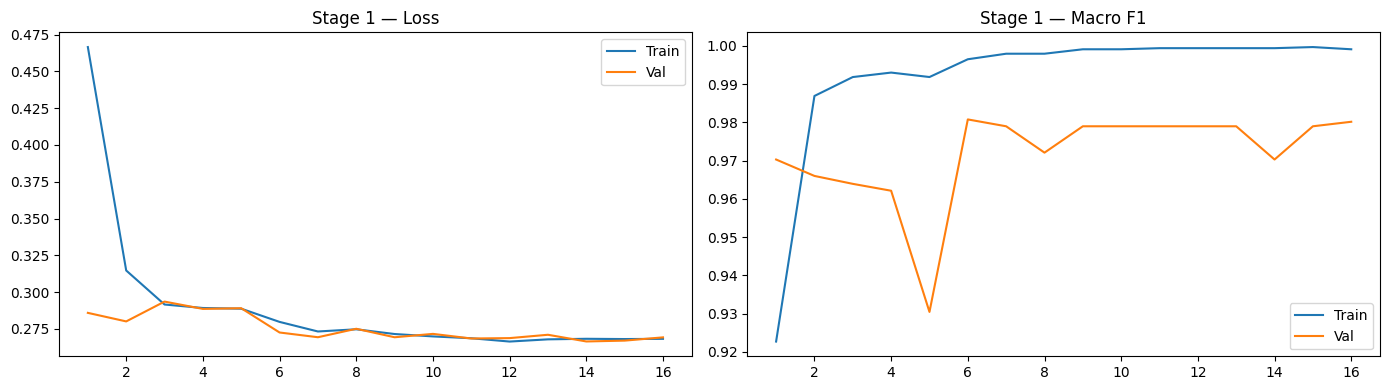

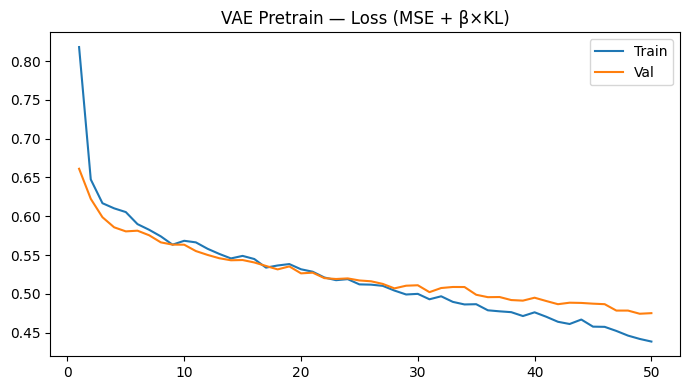

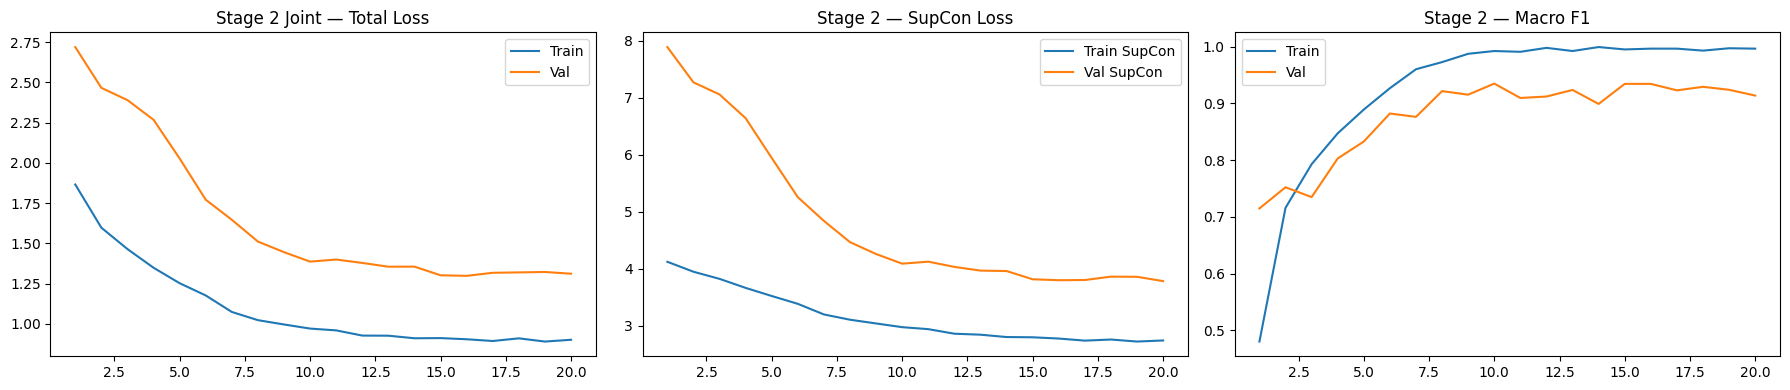

In [19]:
# Stage 1
ep1 = range(1, len(history_stage1["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(ep1, history_stage1["train_loss"], label="Train")
axes[0].plot(ep1, history_stage1["val_loss"],   label="Val")
axes[0].set_title("Stage 1 — Loss")
axes[0].legend()
axes[1].plot(ep1, history_stage1["train_macro_f1"], label="Train")
axes[1].plot(ep1, history_stage1["val_macro_f1"],   label="Val")
axes[1].set_title("Stage 1 — Macro F1")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "stage1_curves.png", dpi=300, bbox_inches="tight")
plt.show()

# VAE pretrain
ep_vae = range(1, len(history_vae["train_loss"]) + 1)
plt.figure(figsize=(7, 4))
plt.plot(ep_vae, history_vae["train_loss"], label="Train")
plt.plot(ep_vae, history_vae["val_loss"],   label="Val")
plt.title("VAE Pretrain — Loss (MSE + β×KL)")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "vae_pretrain_loss.png", dpi=300, bbox_inches="tight")
plt.show()

# Stage 2 joint
ep2 = range(1, len(history_s2["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(ep2, history_s2["train_loss"], label="Train")
axes[0].plot(ep2, history_s2["val_loss"],   label="Val")
axes[0].set_title("Stage 2 Joint — Total Loss")
axes[0].legend()

axes[1].plot(ep2, history_s2["train_supcon"], label="Train SupCon")
axes[1].plot(ep2, history_s2["val_supcon"],   label="Val SupCon")
axes[1].set_title("Stage 2 — SupCon Loss")
axes[1].legend()

axes[2].plot(ep2, history_s2["train_macro_f1"], label="Train")
axes[2].plot(ep2, history_s2["val_macro_f1"],   label="Val")
axes[2].set_title("Stage 2 — Macro F1")
axes[2].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "stage2_joint_curves.png", dpi=300, bbox_inches="tight")
plt.show()

### Bước 18. Suy luận phân cấp 2-stage + Soft Ensemble (MLP + XGBoost)

Xác suất Stage 2 cuối = `w_mlp × prob_mlp + w_xgb × prob_xgb`

In [20]:
# ── Stage 1 inference ──────────────────────────────────────────────────────────
_, val_pred_stage1,  val_prob_stage1  = predict_proba_stage1(stage1_model, val_loader_stage1,  DEVICE)
_, test_pred_stage1, test_prob_stage1 = predict_proba_stage1(stage1_model, test_loader_stage1, DEVICE)

stage1_pred_labels_val  = label_encoder_stage1.inverse_transform(val_pred_stage1)
stage1_pred_labels_test = label_encoder_stage1.inverse_transform(test_pred_stage1)

# ── Stage 2 — chuẩn bị toàn bộ val/test qua selector + scaler Stage 2 ────────
# Val
X_val_all_s2_mm = minmax_stage2.transform(selector_stage2.inverse_transform(
    np.zeros((len(X_val), TOP_K_STAGE2))
) * 0)  # placeholder — dùng raw

# Cách đúng: dùng selector_stage2 để transform toàn bộ X_val/X_test
# selector_stage2 được fit trên minmax của Stage2_raw; áp lên toàn bộ dataset
# cần minmax toàn bộ trước
minmax_all = MinMaxScaler()
# Fit trên X_train toàn bộ để transform val/test
minmax_all.fit(X_train)
X_val_mm_all  = minmax_all.transform(X_val)
X_test_mm_all = minmax_all.transform(X_test)

# Lấy đúng gene đã chọn ở Stage 2 (từ raw index)
X_val_all_s2_raw  = X_val[:, selected_idx_stage2]
X_test_all_s2_raw = X_test[:, selected_idx_stage2]

X_val_all_s2_fs  = scaler_stage2.transform(X_val_all_s2_raw)
X_test_all_s2_fs = scaler_stage2.transform(X_test_all_s2_raw)

# MLP prob từ joint VAE
def get_mlp_proba_all(model, X_np, device, batch_size=64):
    model.eval()
    ds     = GeneDataset(X_np, np.zeros(len(X_np), dtype=int))
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False)
    probs  = []
    with torch.no_grad():
        for xb, _ in loader:
            xb = xb.to(device)
            logits, _, _, _, _ = model(xb)
            probs.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.vstack(probs)

val_prob_s2_mlp  = get_mlp_proba_all(stage2_joint, X_val_all_s2_fs,  DEVICE)
test_prob_s2_mlp = get_mlp_proba_all(stage2_joint, X_test_all_s2_fs, DEVICE)

# XGBoost prob
Z_val_all  = extract_latent_only(stage2_joint, X_val_all_s2_fs,  DEVICE)
Z_test_all = extract_latent_only(stage2_joint, X_test_all_s2_fs, DEVICE)

val_prob_s2_xgb  = xgb_model.predict_proba(Z_val_all)
test_prob_s2_xgb = xgb_model.predict_proba(Z_test_all)

# Soft ensemble
val_prob_s2_ens  = ENSEMBLE_WEIGHT_MLP * val_prob_s2_mlp  + ENSEMBLE_WEIGHT_XGB * val_prob_s2_xgb
test_prob_s2_ens = ENSEMBLE_WEIGHT_MLP * test_prob_s2_mlp + ENSEMBLE_WEIGHT_XGB * test_prob_s2_xgb

val_pred_s2_ens  = np.argmax(val_prob_s2_ens,  axis=1)
test_pred_s2_ens = np.argmax(test_prob_s2_ens, axis=1)

stage2_pred_labels_val_all  = label_encoder_stage2.inverse_transform(val_pred_s2_ens)
stage2_pred_labels_test_all = label_encoder_stage2.inverse_transform(test_pred_s2_ens)

# ── Hard predictions 6 lớp ────────────────────────────────────────────────────
final_val_pred_labels  = stage1_pred_labels_val.copy()
final_test_pred_labels = stage1_pred_labels_test.copy()

val_myeloid_idx  = np.where(stage1_pred_labels_val  == "Myeloid")[0]
test_myeloid_idx = np.where(stage1_pred_labels_test == "Myeloid")[0]

final_val_pred_labels[val_myeloid_idx]   = stage2_pred_labels_val_all[val_myeloid_idx]
final_test_pred_labels[test_myeloid_idx] = stage2_pred_labels_test_all[test_myeloid_idx]

final_val_pred  = label_encoder_6class.transform(final_val_pred_labels)
final_test_pred = label_encoder_6class.transform(final_test_pred_labels)

# ── Final probabilities 6 lớp ─────────────────────────────────────────────────
s1_idx  = {name: i for i, name in enumerate(class_names_stage1)}
s2_idx  = {name: i for i, name in enumerate(class_names_stage2)}
f6_idx  = {name: i for i, name in enumerate(class_names_6class)}

final_val_prob  = np.zeros((len(X_val),  len(class_names_6class)))
final_test_prob = np.zeros((len(X_test), len(class_names_6class)))

for split, s1_prob, s2_prob_ens, final_prob in [
    ("val",  val_prob_stage1,  val_prob_s2_ens,  final_val_prob),
    ("test", test_prob_stage1, test_prob_s2_ens, final_test_prob),
]:
    final_prob[:, f6_idx["ALL"]]     = s1_prob[:, s1_idx["ALL"]]
    final_prob[:, f6_idx["CLL"]]     = s1_prob[:, s1_idx["CLL"]]
    final_prob[:, f6_idx["Healthy"]] = s1_prob[:, s1_idx["Healthy"]]
    final_prob[:, f6_idx["AML"]]     = s1_prob[:, s1_idx["Myeloid"]] * s2_prob_ens[:, s2_idx["AML"]]
    final_prob[:, f6_idx["CML"]]     = s1_prob[:, s1_idx["Myeloid"]] * s2_prob_ens[:, s2_idx["CML"]]
    final_prob[:, f6_idx["MDS"]]     = s1_prob[:, s1_idx["Myeloid"]] * s2_prob_ens[:, s2_idx["MDS"]]

print("Suy luận 2-stage xong.")
print("Val  → Myeloid:", len(val_myeloid_idx))
print("Test → Myeloid:", len(test_myeloid_idx))

Suy luận 2-stage xong.
Val  → Myeloid: 185
Test → Myeloid: 186


### Bước 19. Đánh giá cuối cùng — 6 lớp

In [21]:
def evaluate_final_predictions(y_true, y_pred, y_prob, class_names, split_name):
    acc            = accuracy_score(y_true, y_pred)
    macro_precision = precision_score(y_true, y_pred, average="macro", zero_division=0)
    macro_recall    = recall_score(y_true, y_pred,    average="macro", zero_division=0)
    macro_f1        = f1_score(y_true, y_pred,        average="macro", zero_division=0)

    y_bin         = label_binarize(y_true, classes=np.arange(len(class_names)))
    auc_macro_ovr = roc_auc_score(y_bin, y_prob, average="macro", multi_class="ovr")

    summary = pd.DataFrame([{
        "split":            split_name,
        "accuracy":         acc,
        "macro_precision":  macro_precision,
        "macro_recall":     macro_recall,
        "macro_f1":         macro_f1,
        "auc_macro_ovr":    auc_macro_ovr
    }])
    report_df = pd.DataFrame(
        classification_report(
            y_true, y_pred,
            target_names=class_names,
            output_dict=True,
            zero_division=0
        )
    ).transpose()
    return summary, report_df


val_summary,  val_report  = evaluate_final_predictions(
    y_val_6class,  final_val_pred,  final_val_prob,  class_names_6class, "validation"
)
test_summary, test_report = evaluate_final_predictions(
    y_test_6class, final_test_pred, final_test_prob, class_names_6class, "test"
)

summary_df = pd.concat([val_summary, test_summary], ignore_index=True)
display(summary_df)

summary_df.to_csv(METRIC_DIR / "summary_metrics.csv", index=False)
val_report.to_csv( METRIC_DIR / "classification_report_validation.csv")
test_report.to_csv(METRIC_DIR / "classification_report_test.csv")

,split,accuracy,macro_precision,macro_recall,macro_f1,auc_macro_ovr
0,validation,0.973545,0.961776,0.949540,0.955000,0.995806
1,test,0.952507,0.947913,0.931819,0.938662,0.994501


### Bước 20. Confusion matrix

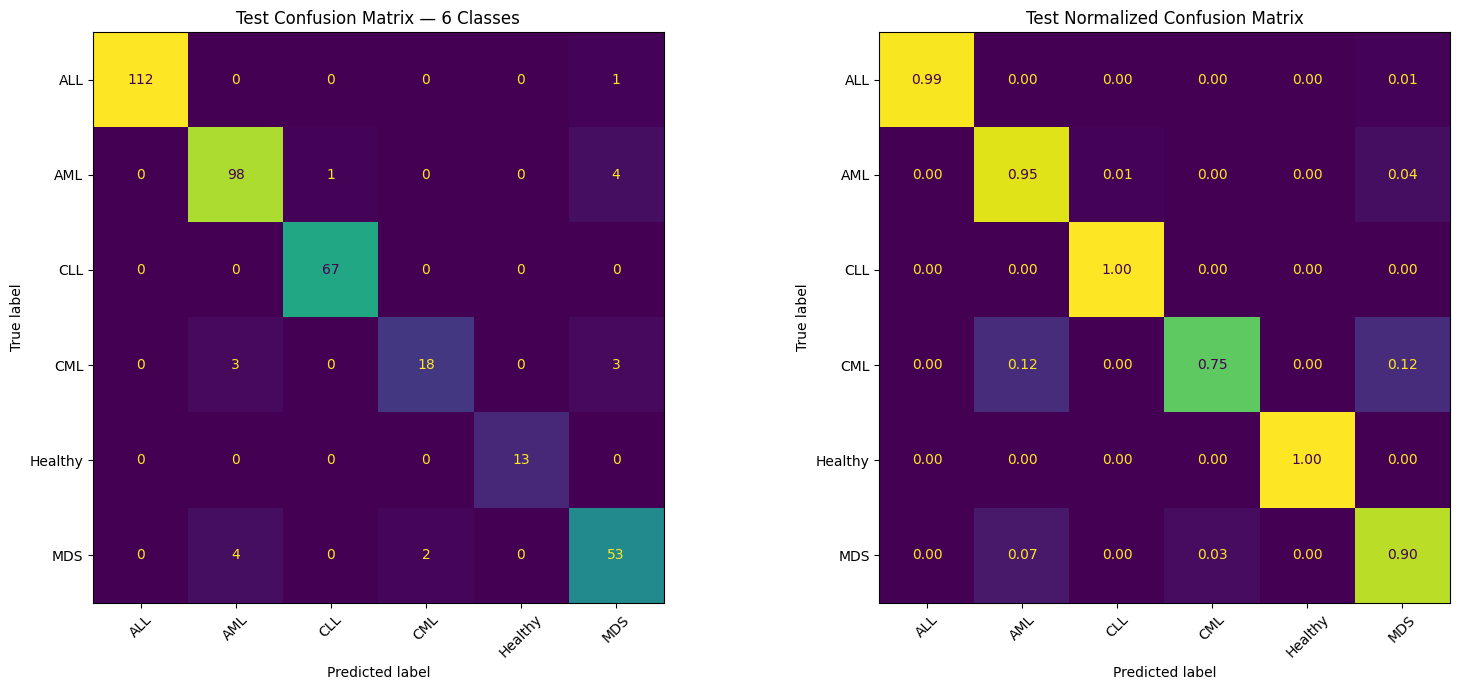

In [22]:
cm = confusion_matrix(y_test_6class, final_test_pred)
pd.DataFrame(cm, index=class_names_6class, columns=class_names_6class).to_csv(
    METRIC_DIR / "final_test_confusion_matrix.csv"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=class_names_6class
).plot(ax=axes[0], xticks_rotation=45, colorbar=False)
axes[0].set_title("Test Confusion Matrix — 6 Classes")

cm_norm = confusion_matrix(y_test_6class, final_test_pred, normalize="true")
ConfusionMatrixDisplay(
    confusion_matrix=cm_norm, display_labels=class_names_6class
).plot(ax=axes[1], xticks_rotation=45, colorbar=False, values_format=".2f")
axes[1].set_title("Test Normalized Confusion Matrix")

plt.tight_layout()
plt.savefig(FIG_DIR / "final_test_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

### Bước 21. Lưu toàn bộ artifacts và nhận xét sơ bộ

In [23]:
# Label encoders
joblib.dump(label_encoder_6class,  MODEL_DIR / "label_encoder_6class.pkl")
joblib.dump(label_encoder_stage1,  MODEL_DIR / "label_encoder_stage1.pkl")
joblib.dump(label_encoder_stage2,  MODEL_DIR / "label_encoder_stage2.pkl")

# Scalers / selectors Stage 1
joblib.dump(minmax_stage1,  MODEL_DIR / "minmax_stage1.pkl")
joblib.dump(scaler_stage1,  MODEL_DIR / "scaler_stage1.pkl")
joblib.dump(selector_stage1, MODEL_DIR / "selector_stage1.pkl")

# Scalers / selectors Stage 2
joblib.dump(minmax_stage2,   MODEL_DIR / "minmax_stage2.pkl")
joblib.dump(scaler_stage2,   MODEL_DIR / "scaler_stage2.pkl")
joblib.dump(selector_stage2, MODEL_DIR / "selector_stage2.pkl")

# SMOTE objects (nếu cần tái sử dụng)
joblib.dump(smote_tomek_stage1 if 'smote_tomek_stage1' in dir() else smote_stage2,
            MODEL_DIR / "smote_stage2.pkl")

test_row = summary_df[summary_df["split"] == "test"].iloc[0]

sep = "=" * 82
print(sep)
print("NHẬN XÉT SƠ BỘ — ex05: VAE + SMOTE-Tomek + SupCon + Ensemble")
print(sep)
print(f"Accuracy test      : {float(test_row['accuracy']):.4f}")
print(f"Macro Precision    : {float(test_row['macro_precision']):.4f}")
print(f"Macro Recall       : {float(test_row['macro_recall']):.4f}")
print(f"Macro F1           : {float(test_row['macro_f1']):.4f}")
print(f"AUC macro OVR      : {float(test_row['auc_macro_ovr']):.4f}")
print(sep)
print("Cải tiến so với ex04:")
print("  [1] Chi² thay ANOVA F-test (học từ [9], [10])")
print("  [2] SMOTE-Tomek tạo mẫu tổng hợp cho lớp thiểu số")
print("  [3] VAE (probabilistic latent) thay Denoising AE (deterministic)")
print("  [4] SupConLoss kéo xa embedding AML/CML/MDS trong latent space")
print("  [5] Soft ensemble ResidualMLP + XGBoost trên latent (học từ [10], [15])")
print(sep)

NHẬN XÉT SƠ BỘ — ex05: VAE + SMOTE-Tomek + SupCon + Ensemble
Accuracy test      : 0.9525
Macro Precision    : 0.9479
Macro Recall       : 0.9318
Macro F1           : 0.9387
AUC macro OVR      : 0.9945
Cải tiến so với ex04:
  [1] Chi² thay ANOVA F-test (học từ [9], [10])
  [2] SMOTE-Tomek tạo mẫu tổng hợp cho lớp thiểu số
  [3] VAE (probabilistic latent) thay Denoising AE (deterministic)
  [4] SupConLoss kéo xa embedding AML/CML/MDS trong latent space
  [5] Soft ensemble ResidualMLP + XGBoost trên latent (học từ [10], [15])
